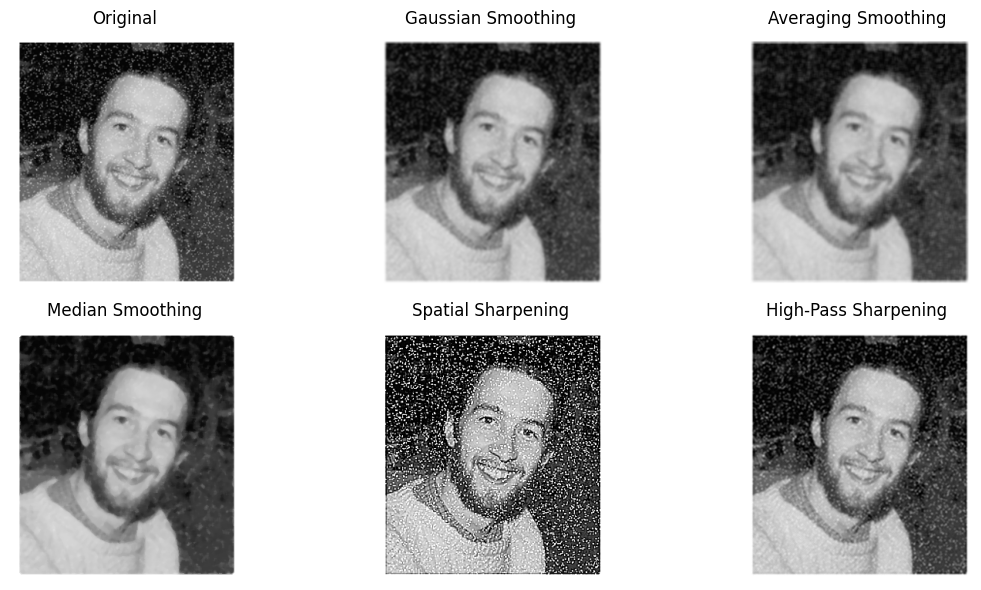

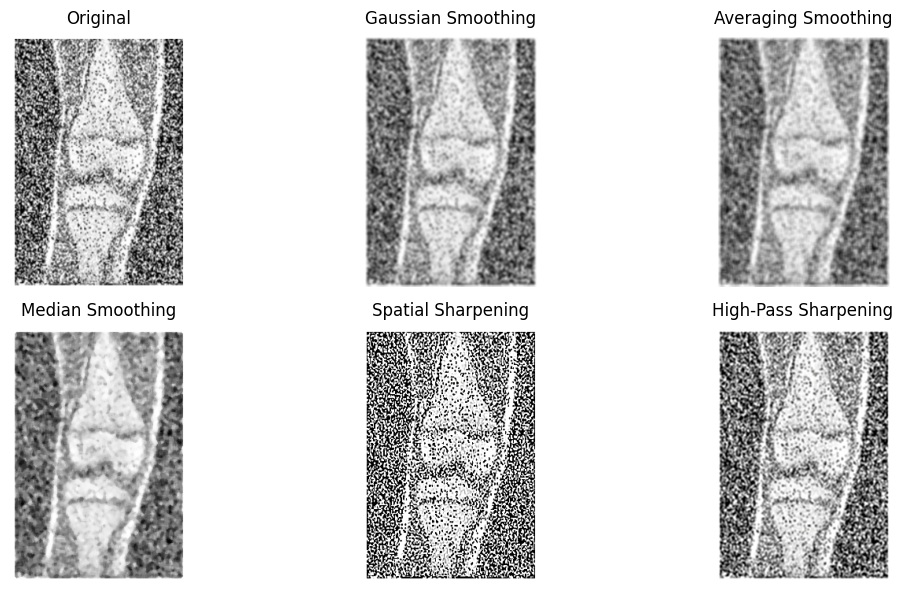

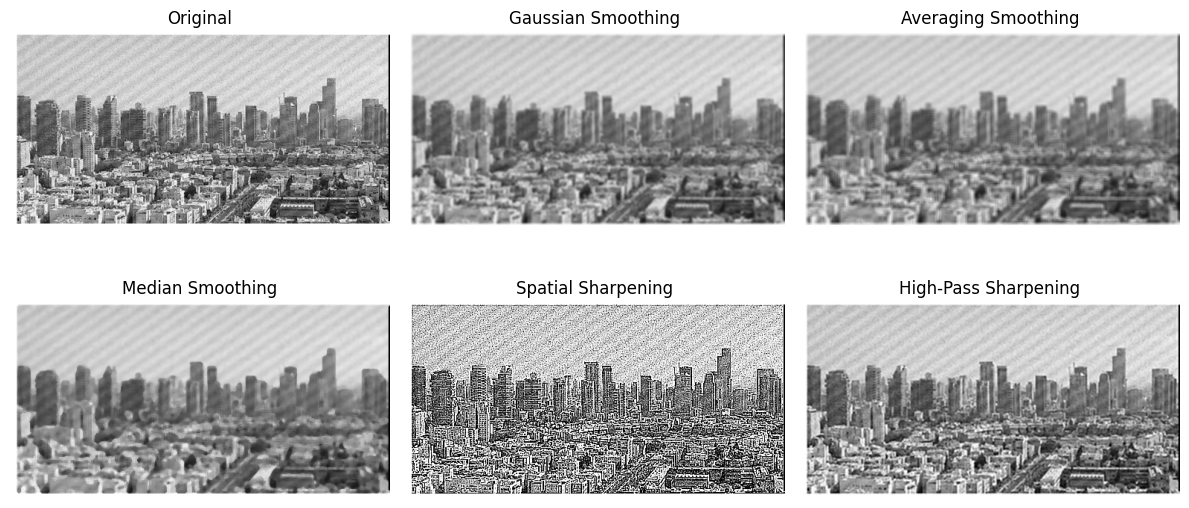

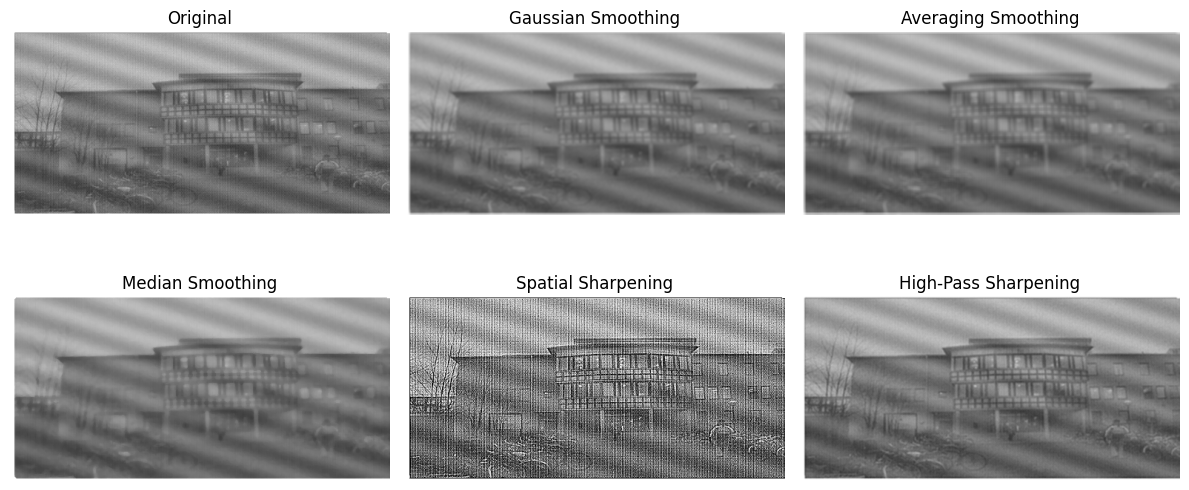

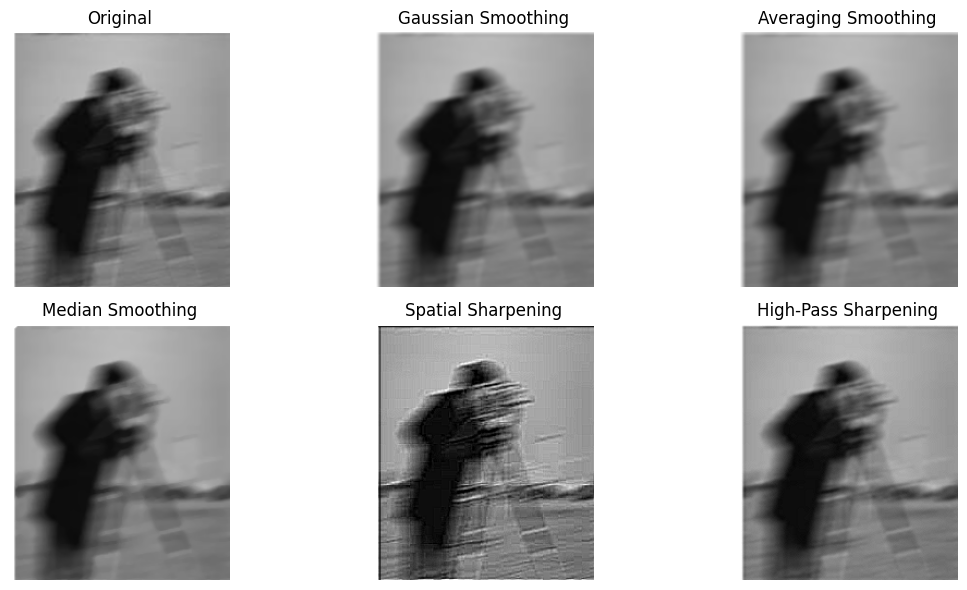

In [6]:

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Input: Five different images
# --------------------------------------------------

image_files = [
    "image1.png",
    "image2.png",
    "image3.png",
    "image4.png",
    "image5.png"
]

output_folder = "Experiment9_Results"
os.makedirs(output_folder, exist_ok=True)


# --------------------------------------------------
# 2. Define smoothing and sharpening filters
# --------------------------------------------------

# Sharpening kernel
sharpening_kernel = np.array([
    [-1, -1, -1],
    [-1,  9, -1],
    [-1, -1, -1]
], dtype=np.float32)

# Spatial high-pass sharpening kernel
highpass_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)


# --------------------------------------------------
# 3. Process each image
# --------------------------------------------------

for image_number, filename in enumerate(image_files, start=1):

    image = cv2.imread(filename)

    if image is None:
        print(f"Skipping {filename}: file not found or unreadable.")
        continue

    # Convert image from BGR to RGB for Matplotlib
    original = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # A. Gaussian smoothing
    gaussian = cv2.GaussianBlur(
        image, (5, 5), 1.5
    )

    # B. Averaging linear filter
    averaging_kernel = np.ones(
        (5, 5), dtype=np.float32
    ) / 25

    averaging = cv2.filter2D(
        image, -1, averaging_kernel
    )

    # C. Median filtering
    median = cv2.medianBlur(image, 5)

    # D. Sharpening using a spatial kernel
    sharpened = cv2.filter2D(
        image, -1, sharpening_kernel
    )

    # E. Gaussian smoothing followed by high-pass sharpening
    blurred = cv2.GaussianBlur(image, (5, 5), 0)

    highpass_sharpened = cv2.filter2D(
        blurred, -1, highpass_kernel
    )

    # Collect all results
    results = {
        "Original": image,
        "Gaussian Smoothing": gaussian,
        "Averaging Smoothing": averaging,
        "Median Smoothing": median,
        "Spatial Sharpening": sharpened,
        "High-Pass Sharpening": highpass_sharpened
    }

    # Save every filtered image
    base_name = os.path.splitext(
        os.path.basename(filename)
    )[0]

    for filter_name, result in results.items():
        safe_name = filter_name.lower().replace(" ", "_")
        output_path = os.path.join(
            output_folder,
            f"{base_name}_{safe_name}.jpg"
        )

        cv2.imwrite(output_path, result)

    # Display original and filtered results in one figure
    fig, axes = plt.subplots(2, 3, figsize=(12, 6))

    for ax, (filter_name, result) in zip(
        axes.flat, results.items()
    ):
        result_rgb = cv2.cvtColor(
            result, cv2.COLOR_BGR2RGB
        )

        ax.imshow(result_rgb)
        ax.set_title(filter_name)
        ax.axis("off")
    plt.tight_layout()

    comparison_path = os.path.join(
        output_folder,
        f"{base_name}_comparison.png"
    )

    plt.savefig(
        comparison_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)
